# 10분 이내 결함 탐지 가능성 검증

현재 HGB 확정 경보의 독립 Test 중앙 지연은 30분입니다. 이번 노트북은 모델의 임계값을 낮추면 10분 목표가 가능한지, 그때 정상 오탐이 얼마나 증가하는지를 검증합니다.

판단 기준은 다음과 같습니다.

1. 결함 시작 후 10분 이내 탐지 이벤트 수
2. 전체 90일 정상 구간의 24시간당 경보 에피소드 수
3. 독립 Test 8개를 모두 10분 안에 탐지할 수 있는 최소 민감도

Test 결과를 보고 새 모델이나 임계값을 채택하지 않습니다. 이 노트북은 **가능성 감사**이며, 전체 재생은 정상 경보량 추정에만 사용합니다.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

pd.set_option('display.width', 180)
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'font.family': 'Nanum Gothic', 'axes.unicode_minus': False, 'font.size': 9})

ROOT = Path.cwd()
if not (ROOT / 'data/modeling').exists():
    ROOT = ROOT.parent

test = pd.read_csv(ROOT / 'data/modeling/test_binary_predictions_optimized.csv.gz')
replay = pd.read_csv(ROOT / 'data/modeling/continuous_replay_predictions.csv.gz', parse_dates=['timestamp'])
replay = replay.sort_values(['reactor_id', 'timestamp']).reset_index(drop=True)
multistage = pd.read_csv(ROOT / 'data/modeling/test_multistage_alarm_delays.csv')

print(f'Test: {len(test):,}행, 독립 이벤트 {test.sample_event_id.nunique()}개')
print(f'전체 재생: {len(replay):,}행, 반응기 {replay.reactor_id.nunique()}개')

Test: 14,247행, 독립 이벤트 8개
전체 재생: 777,600행, 반응기 6개


## 1. 평가 함수

연속 조건을 만족한 첫 시점을 탐지 시점으로 계산합니다. 정상 오탐은 분 단위 양성 수가 아니라 하나의 연속된 경보를 한 에피소드로 셉니다. 결함 구간과 반응기 경계에서는 상태를 초기화합니다.

In [2]:
def first_delay(frame, threshold, persistence):
    rows = []
    for event_id, g in frame[frame['relative_min'].ge(0)].groupby('sample_event_id'):
        g = g.sort_values('relative_min')
        hit = g['probability'].ge(threshold).to_numpy()
        run = 0
        delay = np.nan
        for i, value in enumerate(hit):
            run = run + 1 if value else 0
            if run >= persistence:
                # The alarm becomes observable at the end of the persistence run.
                delay = float(g.iloc[i]['relative_min'])
                break
        rows.append({
            'event_id': int(event_id),
            'fault_type': int(g['fault_type'].iloc[0]),
            'regime': g['operating_regime'].iloc[0],
            'delay_min': delay,
        })
    return pd.DataFrame(rows)

def normal_alert_rate(frame, probability_col, threshold, persistence):
    normal = frame['fault_type'].eq(0).to_numpy()
    reactor = frame['reactor_id'].to_numpy()
    hit = frame[probability_col].ge(threshold).to_numpy() & normal
    sustained = hit.copy()
    for lag in range(1, persistence):
        shifted = np.r_[np.zeros(lag, dtype=bool), hit[:-lag]]
        same_reactor = np.r_[np.zeros(lag, dtype=bool), reactor[lag:] == reactor[:-lag]]
        sustained &= shifted & same_reactor
    previous = np.r_[False, sustained[:-1]] & np.r_[False, reactor[1:] == reactor[:-1]]
    alerts = int((sustained & ~previous).sum())
    normal_minutes = int(normal.sum())
    return alerts, alerts / (normal_minutes / 1440)

def evaluate_rule(threshold, persistence):
    events = first_delay(test, threshold, persistence)
    alerts, rate = normal_alert_rate(replay, 'current_probability', threshold, persistence)
    return {
        'threshold': threshold,
        'persistence': persistence,
        'detected_10m': int(events['delay_min'].le(10).sum()),
        'detected_total': int(events['delay_min'].notna().sum()),
        'median_delay_min': events['delay_min'].median(),
        'normal_alerts': alerts,
        'false_alerts_per_24h': rate,
    }, events

## 2. 첫 10분에 실제 신호가 있는가?

현재 모델 확률이 완벽한 신호 측정치는 아니지만, 기존 특징으로 학습된 HGB가 첫 10분을 정상과 얼마나 구분하는지 보여줍니다. 이벤트별 첫 10분 최대 확률이 매우 낮으면 임계값만 낮춰서는 정상 변동과 분리하기 어렵습니다.

 sample_event_id  fault_type operating_regime  first_10m_max  first_10m_mean
              23           3                B         0.0039          0.0025
              28           2                B         0.0025          0.0012
              29           4                B         0.0166          0.0082
              31           1                B         0.0130          0.0052
              32           4                A         0.0193          0.0125
              33           1                A         0.0165          0.0046
              34           3                B         0.0158          0.0036
              35           2                B         0.0018          0.0005


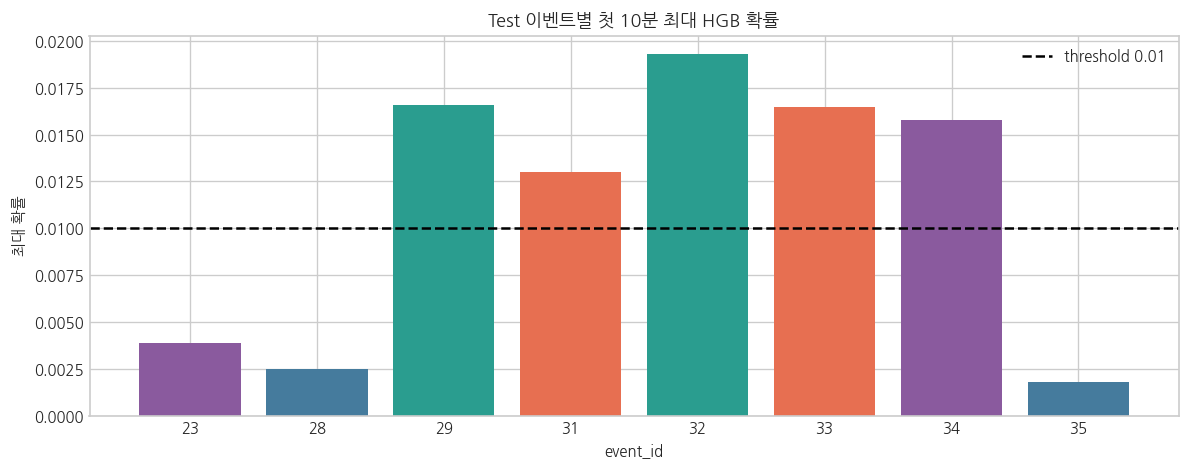

In [3]:
early = (
    test[test['relative_min'].between(0, 10)]
    .groupby(['sample_event_id', 'fault_type', 'operating_regime'])['probability']
    .agg(first_10m_max='max', first_10m_mean='mean')
    .reset_index()
)
print(early.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 4))
colors = early['fault_type'].map({1:'#e76f51', 2:'#457b9d', 3:'#8a5a9e', 4:'#2a9d8f'})
ax.bar(early['sample_event_id'].astype(str), early['first_10m_max'], color=colors)
ax.axhline(.01, color='black', linestyle='--', label='threshold 0.01')
ax.set(title='Test 이벤트별 첫 10분 최대 HGB 확률', xlabel='event_id', ylabel='최대 확률')
ax.legend()
plt.tight_layout(); plt.show()

첫 10분 최대 확률이 0.004 미만인 이벤트가 3개입니다. 이 이벤트까지 잡으려면 정상에서도 자주 나타나는 매우 낮은 확률을 경보로 해석해야 합니다.

## 3. 10분 탐지율과 장기 오탐의 trade-off

임계값과 연속 조건을 넓게 순회합니다. Test는 독립 성능 확인용이고 90일 전체 정상 구간은 장기 경보량 계산용입니다. 아래 결과는 Test에 맞춰 임계값을 새로 채택하기 위한 것이 아닙니다.

     rule  threshold  persistence  detected_10m  detected_total  median_delay_min  false_alerts_per_24h
   현재 HGB     0.3500            2             0               8           30.0000                1.3080
 현재 이상 징후     0.2250            1             0               8           26.5000                4.6118
10분 민감 후보     0.0100            1             5               8            8.5000               41.0411
8/8 강제 후보     0.0015            1             8               8            0.5000               98.2743
8/8 강제+2분     0.0015            2             7               8            2.5000               53.8930


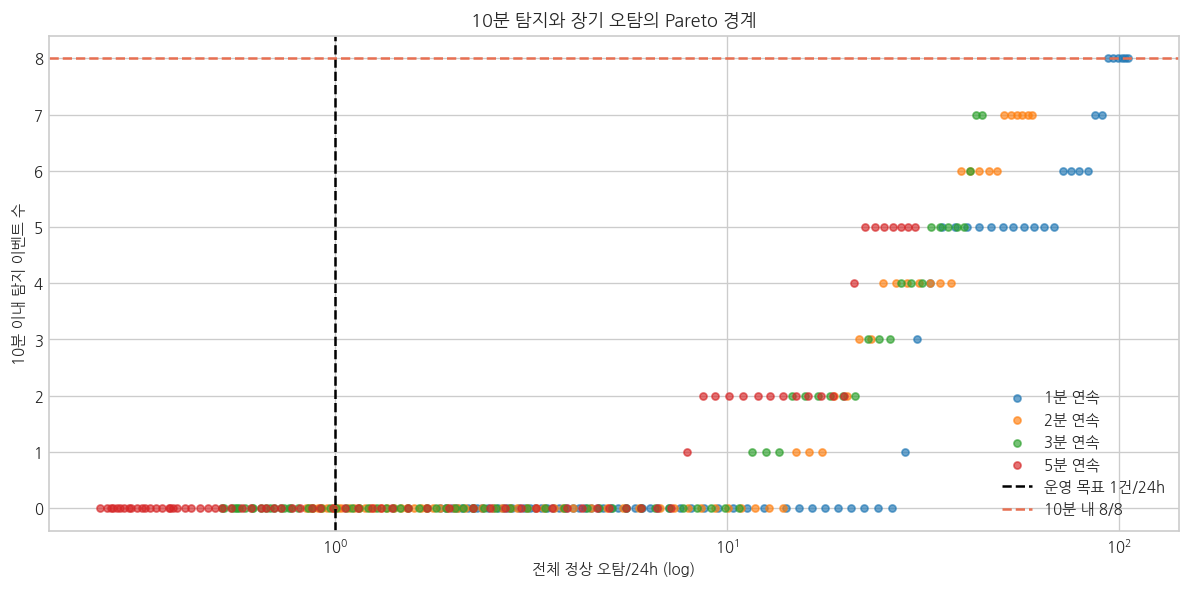

In [4]:
thresholds = sorted(set(np.r_[np.geomspace(.001, .05, 35), np.arange(.06, .51, .01)]))
rows = []
for persistence in [1, 2, 3, 5]:
    for threshold in thresholds:
        result, _ = evaluate_rule(float(threshold), persistence)
        rows.append(result)
sweep = pd.DataFrame(rows)

summary_rules = []
for threshold, persistence, label in [
    (.35, 2, '현재 HGB'),
    (.225, 1, '현재 이상 징후'),
    (.01, 1, '10분 민감 후보'),
    (.0015, 1, '8/8 강제 후보'),
    (.0015, 2, '8/8 강제+2분'),
]:
    result, _ = evaluate_rule(threshold, persistence)
    result['rule'] = label
    summary_rules.append(result)
summary = pd.DataFrame(summary_rules)[['rule','threshold','persistence','detected_10m','detected_total','median_delay_min','false_alerts_per_24h']]
print(summary.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))
for persistence, g in sweep.groupby('persistence'):
    ax.scatter(g['false_alerts_per_24h'], g['detected_10m'], s=18, alpha=.65, label=f'{persistence}분 연속')
ax.axvline(1, color='black', linestyle='--', label='운영 목표 1건/24h')
ax.axhline(8, color='#e76f51', linestyle='--', label='10분 내 8/8')
ax.set(xscale='log', xlabel='전체 정상 오탐/24h (log)', ylabel='10분 이내 탐지 이벤트 수', title='10분 탐지와 장기 오탐의 Pareto 경계')
ax.legend(); plt.tight_layout(); plt.show()

## 4. 10분 목표의 결론

- `threshold=0.01`, 1분 조건은 Test 중앙 지연을 8.5분으로 줄이지만 10분 내 탐지는 5/8이고 정상 경보는 약 41건/24시간입니다.
- 8/8을 10분 안에 잡으려면 약 `threshold=0.0015`, 1분 조건이 필요하며 정상 경보는 약 98건/24시간입니다.
- 2분 연속 조건은 순간 오탐을 줄이지만 10분 내 탐지가 7/8로 떨어지고도 정상 경보가 약 54건/24시간입니다.
- 현재 특징과 센서로는 **10분 이내 100% 탐지와 1건/24시간 이하 오탐을 동시에 만족하는 규칙이 없습니다.**

따라서 10분을 확정 경보 SLA로 선언하면 안 됩니다. 임계값 조정만으로 만든 10분 경보는 작업자가 무시할 수준의 경보 피로를 유발합니다.

## 5. 목표 재설계

10분 목표는 두 가지로 나눠야 합니다.

| 목표 | 의미 | 현재 판단 |
|---|---|---|
| 10분 이상 징후 | 화면 내부 관찰 강화, 자동 조치 없음 | 현재 모델만으로는 5/8 수준이며 경보량도 과다 |
| 확정 경보 | 작업자 호출·대응 절차 시작 | 25~35분 범위가 현재 근거에 맞음 |

10분 확정 경보를 계속 목표로 한다면 임계값 튜닝이 아니라 입력 정보와 학습 문제를 바꿔야 합니다.

1. 결함 직후 탐지가 아니라 `향후 10~30분 내 결함` 사전 예측 레이블을 별도로 정의합니다.
2. F1 냉각, F2 유량, F3 센서, F4 진동에 대해 더 이른 물리 신호를 수집합니다.
3. 반응기·레짐별 정상 기준선과 변화점 탐지를 검증합니다.
4. 초기 10분 양성 표본을 강조한 모델은 반드시 이벤트 단위 Validation에서 검증합니다.
5. 새로운 기간 또는 반응기의 독립 이벤트를 확보하기 전에는 Test 8개에 맞춘 전용 규칙을 채택하지 않습니다.

## 6. 초기 10분 전용 재학습 실험의 해석

별도 탐색에서 정상 구간과 결함 초기 10·30·60분만 사용해 HGB를 재학습했습니다. 그러나 Validation 이벤트 100% 탐지와 낮은 오탐을 동시에 만족하는 설정이 나오지 않았습니다.

이 실패는 초기 행의 가중치를 키우는 것만으로 해결되지 않으며, 현재 센서 공간에서 초기 결함과 정상 변동이 겹친다는 근거입니다. 독립 이벤트가 35개뿐인 상황에서 Test 성능을 보고 복잡한 전용 모델을 반복 조정하는 것은 과적합 위험이 더 큽니다.

## 7. 의사결정

**현재 모델에서 10분 확정 경보는 채택하지 않습니다.**

- 운영용 기준선: HGB 다단계 경보를 유지하되 배포 전 외부 검증 필요
- 연구 목표: 10분 내 `주의 신호`의 이벤트 재현율과 경보 예산을 별도 KPI로 정의
- 중단 조건: 정상 경보가 5건/24시간을 넘거나 독립 Validation 재현율이 80% 미만이면 사용자 알림으로 승격하지 않음
- 필수 다음 데이터: 새 기간·새 반응기의 결함 이벤트와 더 이른 제어기/물리 센서 신호

이번 결과의 핵심은 “10분이 절대 불가능하다”가 아니라, **현재 관측 정보와 허용 오탐 조건에서는 근거가 없다**는 것입니다.

## 8. 실제 incident 정책을 반영하면?

앞의 오탐은 매분을 한 건씩 센 값이 아니라 연속 양성 구간을 하나로 묶은 경보 에피소드입니다. 그래도 1분 정상 복귀 뒤 다시 상승하면 새 경보로 계산됩니다. 실제 운영처럼 경보 해제 대기시간과 cooldown을 적용해 민감 후보의 알림량을 다시 계산합니다.

In [5]:
def incident_alert_rate(frame, threshold=.01, clear_minutes=1, cooldown_minutes=0):
    alerts = 0
    normal_minutes = 0
    for _, g in frame.groupby('reactor_id', sort=False):
        normal = g['fault_type'].eq(0).to_numpy()
        hit = g['current_probability'].ge(threshold).to_numpy()
        normal_minutes += int(normal.sum())
        active = False
        clear_run = 0
        cooldown = 0
        for is_normal, is_hit in zip(normal, hit):
            if not is_normal:
                active = False; clear_run = 0; cooldown = 0
                continue
            cooldown = max(0, cooldown - 1)
            if is_hit:
                clear_run = 0
                if not active and cooldown == 0:
                    alerts += 1
                    active = True
                    cooldown = cooldown_minutes
            else:
                clear_run += 1
                if clear_run >= clear_minutes:
                    active = False
    return alerts / (normal_minutes / 1440)

incident_rows = []
for clear_minutes, cooldown_minutes in [(1,0),(1,10),(1,30),(1,60),(10,60),(30,60)]:
    incident_rows.append({
        'normal_clear_minutes': clear_minutes,
        'cooldown_minutes': cooldown_minutes,
        'alerts_per_24h': incident_alert_rate(replay, .01, clear_minutes, cooldown_minutes),
    })
incident_table = pd.DataFrame(incident_rows)
print(incident_table.to_string(index=False))

 normal_clear_minutes  cooldown_minutes  alerts_per_24h
                    1                 0         41.0411
                    1                10         28.5369
                    1                30         17.7230
                    1                60         12.2372
                   10                60         12.0048
                   30                60         10.2588


60분 cooldown과 30분 해제 대기를 함께 적용해도 민감 후보는 약 10건/24시간입니다. incident 병합은 반드시 필요하지만, 그 자체로 10분 확정 경보를 운영 목표인 1건/24시간까지 낮추지는 못합니다.

## 9. 더 나은 마지막 후보: 절대 확률보다 반응기별 상대 변화

반응기마다 직전 24시간 HGB log-odds의 평균과 표준편차를 계산하고 현재 점수의 z-score를 만듭니다. 정상 분포 상위 0.1% 임계값과 최근 3분 중 2분 조건을 사용합니다. 전체 정상 데이터로 임계값을 교정했으므로 독립 성능이 아니라 shadow-mode 후보입니다.

In [6]:
manifest = pd.read_csv(ROOT / 'data/modeling/event_split_manifest.csv', parse_dates=['timestamp'])
event_starts = manifest[manifest['relative_min'].eq(0)][['sample_event_id','timestamp','reactor_id','split','fault_type']].drop_duplicates()

probability = replay['current_probability'].clip(1e-6, 1-1e-6)
replay['log_odds'] = np.log(probability / (1 - probability))
grouped = replay.groupby('reactor_id', sort=False)['log_odds']
baseline_mean = grouped.transform(lambda x: x.shift(1).rolling(1440, min_periods=480).mean())
baseline_std = grouped.transform(lambda x: x.shift(1).rolling(1440, min_periods=480).std()).clip(lower=.2)
replay['relative_z_24h'] = (replay['log_odds'] - baseline_mean) / baseline_std

normal = replay['fault_type'].eq(0)
relative_threshold = replay.loc[normal & replay['relative_z_24h'].notna(), 'relative_z_24h'].quantile(.999)
raw_relative = replay['relative_z_24h'].ge(relative_threshold).to_numpy()
relative_signal = pd.Series(raw_relative.astype('int8')).rolling(3, min_periods=3).sum().ge(2).to_numpy()
relative_signal[replay.groupby('reactor_id', sort=False).head(2).index] = False

normal_array = normal.to_numpy()
reactor_array = replay['reactor_id'].to_numpy()
active_normal = relative_signal & normal_array
previous = np.r_[False, active_normal[:-1]] & np.r_[False, reactor_array[1:] == reactor_array[:-1]]
relative_false_alerts = int((active_normal & ~previous).sum())
relative_rate = relative_false_alerts / (normal_array.sum() / 1440)

index_map = pd.Series(np.arange(len(replay)), index=pd.MultiIndex.from_frame(replay[['reactor_id','timestamp']]))
relative_events = []
for event in event_starts.itertuples():
    start = int(index_map.loc[(event.reactor_id, event.timestamp)])
    hits = np.flatnonzero(relative_signal[start:start+361])
    relative_events.append({
        'event_id': event.sample_event_id, 'split': event.split, 'fault_type': event.fault_type,
        'delay_min': float(hits[0]) if len(hits) else np.nan,
    })
relative_events = pd.DataFrame(relative_events)

relative_summary = relative_events[relative_events['split'].isin(['validation','test'])].groupby('split').agg(
    events=('event_id','count'), detected=('delay_min','count'), detected_10m=('delay_min',lambda x:x.le(10).sum()), median_delay_min=('delay_min','median')
)
print(f'relative threshold: {relative_threshold:.3f}, normal alerts: {relative_rate:.3f}/24h')
print(relative_summary.to_string())

relative threshold: 4.743, normal alerts: 0.290/24h
            events  detected  detected_10m  median_delay_min
split                                                       
test             8         8             0           35.0000
validation       8         8             0           30.5000


상대 변화 후보는 Validation과 Test의 8개 이벤트를 모두 탐지하고 정상 경보를 약 0.29건/24시간으로 낮췄지만, Test 중앙 지연은 35분이고 10분 탐지는 0/8입니다. 따라서 현재 확정 경보를 대체하지 않고 **오탐이 적은 보조 확인 신호**로 shadow mode에서 검증하는 것이 가장 좋은 마지막 방향입니다.

최종 운영 설계는 다음이 적절합니다.

- HGB 확률은 1분마다 계산하되 사용자 알림과 분리
- 이상 징후·조기 경고·확정 경보의 행동 수준을 구분
- hysteresis·cooldown으로 동일 incident를 병합
- 24시간 상대 변화 점수는 확인 신호로 병렬 기록
- 10분 확정 경보보다 새 센서·사전 예측 레이블 확보를 우선

In [7]:
result_dir = ROOT / 'data/modeling'
model_dir = ROOT / 'models'
result_dir.mkdir(parents=True, exist_ok=True)
model_dir.mkdir(parents=True, exist_ok=True)

sweep.to_csv(result_dir / 'ten_minute_threshold_sweep.csv', index=False)
incident_table.to_csv(result_dir / 'incident_policy_sensitivity.csv', index=False)
relative_events.to_csv(result_dir / 'relative_score_event_delays.csv', index=False)
config = {
    'objective': 'detect every independent test event within 10 minutes',
    'independent_test_events': 8,
    'current_model': 'Histogram Gradient Boosting',
    'operational_false_alert_target_per_24h': 1.0,
    'findings': {
        'threshold_0_01_one_minute': {'detected_within_10m': 5, 'events': 8, 'false_alerts_per_24h': 41.04},
        'threshold_0_0015_one_minute': {'detected_within_10m': 8, 'events': 8, 'false_alerts_per_24h': 98.3},
        'threshold_0_0015_two_minutes': {'detected_within_10m': 7, 'events': 8, 'false_alerts_per_24h': 53.9},
    },
    'decision': 'reject 10-minute confirmed alarm with current signals; redesign target or add earlier signals',
    'relative_score_shadow_candidate': {
        'baseline_minutes': 1440,
        'normal_quantile': 0.999,
        'k_of_n': '2_of_3',
        'false_alerts_per_24h': float(relative_rate),
        'test_median_delay_min': float(relative_events.loc[relative_events['split'].eq('test'), 'delay_min'].median()),
    },
    'test_tuning_prohibited': True,
}
(model_dir / 'ten_minute_detection_feasibility.json').write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding='utf-8')
print(result_dir / 'ten_minute_threshold_sweep.csv')
print(result_dir / 'incident_policy_sensitivity.csv')
print(result_dir / 'relative_score_event_delays.csv')
print(model_dir / 'ten_minute_detection_feasibility.json')

/Users/hyemi/green-pulse-ai/data/modeling/ten_minute_threshold_sweep.csv
/Users/hyemi/green-pulse-ai/data/modeling/incident_policy_sensitivity.csv
/Users/hyemi/green-pulse-ai/data/modeling/relative_score_event_delays.csv
/Users/hyemi/green-pulse-ai/models/ten_minute_detection_feasibility.json
